# 🌦️ NOAA Weather Time Series Analysis
**Cohort Time Series Project**

This notebook walks through an end-to-end time series analysis workflow using NOAA weather observations. We cover:
1. **Date Parsing & Schema Standardization**: Converting raw text dates and tabular date fields into native Pandas `Timestamp` objects.
2. **Date Sequences & Datetime Indexing**: Generating regular calendar grids using `pd.date_range()` and unlocking date-based partial string slicing with `DatetimeIndex`.
3. **Resampling & Rolling Averages**: Handling irregular station observations, constructing a continuous temporal grid, and smoothing noise with rolling moving averages.
4. **Temporal Feature Extraction**: Isolating calendar components (`month`, `day_of_week`) to discover seasonal weather patterns.
5. **Visual Trend Analysis**: Plotting raw observations alongside moving average trendlines for clear visual interpretation.


---
## Step 1: Loading the Dataset & Parsing Dates (`pd.to_datetime`)

### Specific Task
Load the NOAA weather dataset, inspect its column structure, and parse the date fields into Pandas `Timestamp` objects using `pd.to_datetime()`.

### Intuitive Explanation
In raw datasets, dates are frequently stored as plain strings or partitioned across separate columns (`year`, `month`, `day`). By converting them into native Pandas `datetime64` representations, Pandas automatically understands chronological order, leap years, days of the week, and temporal arithmetic.


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Load the NOAA weather dataset (using relative path for portability)
csv_filename = "noaa - 5000.csv"
if not os.path.exists(csv_filename):
    csv_filename = r"C:\Users\DEELL\Documents\antgravity2-projects\Time-series-project\noaa - 5000.csv"

df = pd.read_csv(csv_filename)

# 2. Parse the text date column directly into Pandas Timestamp objects
df['date'] = pd.to_datetime(df['date'])

# 3. Demonstrate parsing by combining separate year, month, and day fields
df['date_from_fields'] = pd.to_datetime(
    df[['year', 'mo', 'da']].rename(columns={'year': 'year', 'mo': 'month', 'da': 'day'})
)

print("Dataset Overview (First 5 Rows):")
print(df[['stn', 'wban', 'date', 'temp', 'dewp', 'prcp']].head())
print("\nDate Column Data Types:")
print(df[['date', 'date_from_fields']].dtypes)


Dataset Overview (First 5 Rows):
     stn   wban       date  temp  dewp  prcp
0  10020  99999 2025-07-04  42.1  38.5   0.0
1  10020  99999 2025-04-30   7.6   3.8   0.0
2  10020  99999 2025-04-19   2.7  -2.5   0.0
3  10020  99999 2025-04-20   4.2  -1.0   0.0
4  10020  99999 2025-03-05  14.4  10.0   0.0

Date Column Data Types:
date                datetime64[us]
date_from_fields    datetime64[us]
dtype: object


---
## Step 2: Creating Regular Date Sequences (`pd.date_range`) & Datetime Indexing

### Specific Task
Generate a continuous annual calendar with `pd.date_range()` and set a `DatetimeIndex` on the DataFrame for intuitive date-based slicing.

### Intuitive Explanation
Setting a `DatetimeIndex` turns your DataFrame into a true time series object. Once indexed by time, Pandas allows you to select slices of data intuitively using date strings (for example, passing `'2025-07'` returns all readings from July 2025, or passing `'2025-07-04':'2025-07-20'` returns that exact date range). 

The `pd.date_range()` function generates regular sequences of dates across daily (`'D'`), monthly (`'MS'`), or hourly (`'h'`) frequencies.


In [2]:
# 1. Generate a continuous daily calendar for the entire year 2025
dates_2025 = pd.date_range(start="2025-01-01", end="2025-12-31", freq="D")
print(f"Generated {len(dates_2025)} continuous daily timestamps.")
print("First 5 dates:", dates_2025[:5].strftime('%Y-%m-%d').tolist())

# 2. Create a synthetic annual temperature series demonstration
np.random.seed(42)
temp_synthetic = 55 + 25 * np.sin(2 * np.pi * np.arange(len(dates_2025)) / 365) + np.random.normal(0, 4, len(dates_2025))
annual_ts = pd.DataFrame({'synthetic_temp': temp_synthetic}, index=dates_2025)
annual_ts.index.name = 'date'

# 3. Set DatetimeIndex on the NOAA DataFrame and sort chronologically
df_indexed = df.set_index('date').sort_index()

print("\nIndex Verification:")
print(f"Index Type: {type(df_indexed.index)}")

# 4. Perform intuitive date-based slicing
# Slicing an entire month
july_readings = df_indexed.loc['2025-07']
print(f"\nTotal station observations in July 2025: {len(july_readings)}")

# Slicing a specific date range
summer_window = df_indexed.loc['2025-07-04':'2025-07-20']
print(f"Total observations between 2025-07-04 and 2025-07-20: {len(summer_window)}")
summer_window[['stn', 'temp', 'dewp']].head()


Generated 365 continuous daily timestamps.
First 5 dates: ['2025-01-01', '2025-01-02', '2025-01-03', '2025-01-04', '2025-01-05']

Index Verification:
Index Type: <class 'pandas.DatetimeIndex'>

Total station observations in July 2025: 710
Total observations between 2025-07-04 and 2025-07-20: 400


,stn,temp,dewp
date,,,
2025-07-04,488310,84.2,76.6
2025-07-04,420990,91.1,79.9
2025-07-04,287860,75.1,62.2
2025-07-04,601200,75.5,67.1
2025-07-04,270370,68.5,55.6


---
## Step 3: Continuous Date Grids & Rolling Windows (Moving Averages)

### Specific Task
Compute daily average temperatures across stations, map the series onto a continuous date grid, and calculate a 30-day moving average using `.rolling()`.

### Intuitive Explanation
Daily weather readings contain significant high-frequency noise from sudden cold fronts or short heatwaves. A rolling moving average calculates the average temperature over a moving time window (e.g., 30 days), dampening short-term fluctuations to reveal macro seasonal trajectories.


In [3]:
# 1. Compute daily average temperature across all weather stations
daily_avg_temp = df.groupby('date')['temp'].mean().sort_index()

# 2. Ensure a continuous daily date grid (reindex across the full observation span)
full_date_range = pd.date_range(start=daily_avg_temp.index.min(), end=daily_avg_temp.index.max(), freq='D')
daily_full = daily_avg_temp.reindex(full_date_range)

# 3. Compute 30-day rolling moving average
rolling_30d = daily_full.rolling(window=30, min_periods=1).mean()

# 4. Construct a comparison DataFrame
smoothed_df = pd.DataFrame({
    'raw_daily_temp': daily_full,
    'rolling_30d_temp': rolling_30d
})

print("Daily Temperature & 30-Day Rolling Mean (First 10 Days):")
print(smoothed_df.head(10))


Daily Temperature & 30-Day Rolling Mean (First 10 Days):
            raw_daily_temp  rolling_30d_temp
2025-01-01       50.387500         50.387500
2025-01-02       45.115000         47.751250
2025-01-03       48.352632         47.951711
2025-01-04       43.564286         46.854854
2025-01-05       47.028571         46.889598
2025-01-06       42.575000         46.170498
2025-01-07       38.847619         45.124373
2025-01-08       42.275000         44.768201
2025-01-09       47.921053         45.118518
2025-01-10       50.200000         45.626666


---
## Step 4: Extracting Calendar Attributes & Seasonality Analysis

### Specific Task
Extract calendar properties (`month`, `month_name`, `day_of_week`, `day_name`) directly from the `DatetimeIndex` to evaluate monthly and weekly temperature patterns.

### Intuitive Explanation
A `DatetimeIndex` provides built-in accessor properties for calendar metadata. Grouping by these attributes enables quick discovery of seasonal heating/cooling cycles and verifies whether data collection varies across different days of the week.


In [4]:
# 1. Extract calendar features from the DatetimeIndex
df_indexed['month'] = df_indexed.index.month
df_indexed['month_name'] = df_indexed.index.month_name()
df_indexed['day_of_week'] = df_indexed.index.dayofweek
df_indexed['day_name'] = df_indexed.index.day_name()

# 2. Monthly temperature summary (seasonality)
monthly_summary = df_indexed.groupby(['month', 'month_name'])['temp'].agg(
    mean_temp='mean',
    min_temp='min',
    max_temp='max',
    observation_count='count'
).reset_index().sort_values('month')

print("Monthly Temperature Summary:")
print(monthly_summary.to_string(index=False))

# 3. Day of week temperature summary
dow_summary = df_indexed.groupby(['day_of_week', 'day_name'])['temp'].agg(
    mean_temp='mean',
    observation_count='count'
).reset_index().sort_values('day_of_week')

print("\nDay of Week Temperature Summary:")
print(dow_summary.to_string(index=False))


Monthly Temperature Summary:
 month month_name  mean_temp  min_temp  max_temp  observation_count
     1    January  45.653073     -57.2      93.4                667
     2   February  47.156707     -59.1     102.2                656
     3      March  54.819702     -83.0     102.2                604
     4      April  61.089535     -97.0     104.3                602
     5        May  66.567719    -105.3     104.0                570
     6       June  67.142985     -98.9     107.5                670
     7       July  70.449718    -102.1     102.4                710
     8     August  68.461036     -95.8     109.4                521

Day of Week Temperature Summary:
 day_of_week  day_name  mean_temp  observation_count
           0    Monday  61.977727                660
           1   Tuesday  59.780028                711
           2 Wednesday  60.724038                728
           3  Thursday  58.579714                700
           4    Friday  57.383106                805
       

---
## Step 5: Visualizing Time Series Trends

### Specific Task
Plot the raw daily temperature measurements alongside the 30-day rolling mean to provide clear visual evidence of temporal trends and seasonal progression.

### Intuitive Explanation
Data visualization is the ultimate sanity check in time series analysis. Plotting raw daily readings in a semi-transparent hue alongside a prominent moving average line immediately highlights how rolling windows filter out noise while preserving underlying trends.


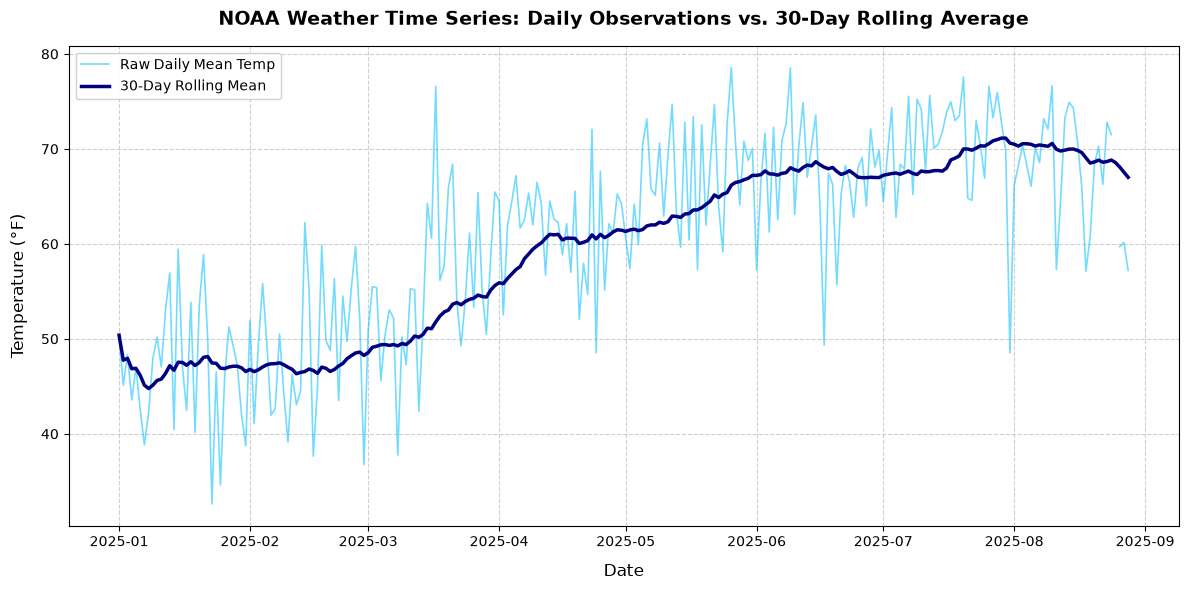

In [5]:
plt.figure(figsize=(12, 6), dpi=100)

# Plot raw daily temperatures
plt.plot(daily_full.index, daily_full, label='Raw Daily Mean Temp', color='deepskyblue', alpha=0.55, linewidth=1.2)

# Plot smoothed 30-day rolling average
plt.plot(rolling_30d.index, rolling_30d, label='30-Day Rolling Mean', color='navy', linewidth=2.5)

# Styling and annotations
plt.title('NOAA Weather Time Series: Daily Observations vs. 30-Day Rolling Average', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Date', fontsize=12, labelpad=10)
plt.ylabel('Temperature (°F)', fontsize=12, labelpad=10)
plt.legend(loc='upper left', frameon=True, facecolor='white', framealpha=0.9)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()

# Display plot
plt.show()


---
## 🎯 Key Takeaways & Project Summary

1. **Date Parsing**: Converting dates to `datetime64[ns]` ensures chronological integrity and eliminates date-format ambiguity.
2. **Datetime Indexing**: Slicing time series with strings like `.loc['2025-07']` simplifies temporal filtering without complex Boolean logic.
3. **Regular Grids & Rolling Windows**: Aligning data to an explicit daily frequency grid (`freq='D'`) ensures accurate moving averages that smooth noisy daily spikes.
4. **Seasonality**: Monthly grouping clearly outlines annual temperature variations from winter lows through summer peaks.
